# Analisis Penjualan Coffee Shop

**Dataset:** Coffee Shop Sales Revenue (transaksi 3 toko di New York, 1 Januari - 30 Juni 2023)

**Alur notebook:**
1. Latar belakang dan pertanyaan bisnis
2. Persiapan dan pemuatan data
3. Pemahaman data
4. Pembersihan data dan pembuatan fitur
5. Analisis untuk menjawab tiap pertanyaan bisnis
6. Kesimpulan dan rekomendasi
7. Keterbatasan analisis

## 1. Latar Belakang dan Pertanyaan Bisnis

**Konteks.** Sebuah jaringan coffee shop memiliki tiga cabang: Astoria, Hell's Kitchen, dan Lower Manhattan. Manajemen ingin memahami performa penjualan semester pertama 2023 untuk menentukan di mana harus menambah stok, mengatur jadwal staf, dan menjalankan promo.

**Pertanyaan bisnis:**

| No | Pertanyaan | Keputusan yang dibantu |
|----|-----------|------------------------|
| Q1 | Bagaimana tren pendapatan bulanan dan harian, dan seberapa cepat tumbuhnya? | Target penjualan dan perencanaan kapasitas |
| Q2 | Bagaimana perbandingan performa ketiga toko? | Alokasi sumber daya antar cabang |
| Q3 | Kategori dan produk apa yang menyumbang pendapatan terbesar? | Prioritas stok dan menu |
| Q4 | Kapan jam dan hari tersibuk, dan apakah polanya sama di setiap toko? | Penjadwalan staf dan jam operasional |
| Q5 | Pertumbuhan pendapatan didorong oleh apa: jumlah transaksi, nilai per transaksi, atau kategori tertentu? | Strategi pertumbuhan |

**Catatan definisi.** Dataset tidak memiliki ID pesanan atau ID pelanggan. Satu baris adalah satu item transaksi, jadi istilah "transaksi" di notebook ini berarti satu baris item. Mata uang diasumsikan USD karena lokasi toko di New York (tidak disebutkan eksplisit di dataset).

## 2. Persiapan dan Pemuatan Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.2f}".format

WARNA = "#6f4e37"  # warna utama (cokelat kopi)

In [2]:
FILE_NAME = "coffee-shop-sales-revenue.csv"

if not os.path.exists(FILE_NAME):
    try:
        from google.colab import files
        print("Silakan unggah file CSV...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"File {FILE_NAME} tidak ditemukan di folder kerja.")

df = pd.read_csv(FILE_NAME, sep="|")
print(f"Jumlah baris: {df.shape[0]:,} | Jumlah kolom: {df.shape[1]}")
df.head()

Jumlah baris: 149,116 | Jumlah kolom: 11


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


## 3. Pemahaman Data

Cek tipe data, nilai kosong, duplikat, dan ringkasan statistik sebelum menganalisis apa pun.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   transaction_date  149116 non-null  object 
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  object 
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  object 
 9   product_type      149116 non-null  object 
 10  product_detail    149116 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 12.5+ MB


In [4]:
print("Nilai kosong per kolom:")
print(df.isna().sum())
print()
print("Baris duplikat penuh      :", df.duplicated().sum())
print("transaction_id duplikat   :", df["transaction_id"].duplicated().sum())

Nilai kosong per kolom:
transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

Baris duplikat penuh      : 0
transaction_id duplikat   : 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_id,"149,116.00","74,737.37","43,153.60",1.00,"37,335.75","74,727.50","112,094.25","149,456.00"
transaction_qty,"149,116.00",1.44,0.54,1.00,1.00,1.00,2.00,8.00
store_id,"149,116.00",5.34,2.07,3.00,3.00,5.00,8.00,8.00
product_id,"149,116.00",47.92,17.93,1.00,33.00,47.00,60.00,87.00
unit_price,"149,116.00",3.38,2.66,0.80,2.50,3.00,3.75,45.00


In [6]:
# Cek konsistensi data master
print("Satu store_id = satu lokasi?      ", df.groupby("store_id")["store_location"].nunique().max() == 1)
print("Satu product_id = satu detail?    ", df.groupby("product_id")["product_detail"].nunique().max() == 1)
print("Satu product_id = satu harga?     ", df.groupby("product_id")["unit_price"].nunique().max() == 1)
print()
print("Jumlah toko     :", df["store_id"].nunique())
print("Jumlah produk   :", df["product_id"].nunique())
print("Jumlah kategori :", df["product_category"].nunique())

Satu store_id = satu lokasi?       True
Satu product_id = satu detail?     True
Satu product_id = satu harga?      False

Jumlah toko     : 3
Jumlah produk   : 80
Jumlah kategori : 9


**Temuan awal:** tidak ada nilai kosong dan tidak ada duplikat. Data master konsisten (satu ID mewakili satu toko, satu produk, dan satu harga).

## 4. Pembersihan Data dan Pembuatan Fitur

Yang dikerjakan:
- Mengubah tanggal dan jam ke format yang benar
- Membuat kolom `revenue` (= `transaction_qty` x `unit_price`)
- Membuat fitur waktu: bulan, hari, jam, dan periode hari
- Memeriksa nilai ekstrem dan kelengkapan tanggal

In [7]:
# Tanggal dan jam
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["hour"] = pd.to_datetime(df["transaction_time"], format="%H:%M:%S").dt.hour

# Pendapatan per baris
df["revenue"] = df["transaction_qty"] * df["unit_price"]

# Fitur waktu
df["month"] = df["transaction_date"].dt.to_period("M").dt.to_timestamp()
df["month_label"] = df["month"].dt.strftime("%b %Y")

hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
df["weekday"] = pd.Categorical(
    df["transaction_date"].dt.dayofweek.map(dict(enumerate(hari))),
    categories=hari, ordered=True,
)
df["day_type"] = np.where(df["transaction_date"].dt.dayofweek >= 5, "Akhir pekan", "Hari kerja")

df["period"] = pd.cut(
    df["hour"],
    bins=[5, 10, 14, 17, 20],
    labels=["Pagi (06-10)", "Siang (11-14)", "Sore (15-17)", "Malam (18-20)"],
)

df[["transaction_date", "hour", "revenue", "month_label", "weekday", "period"]].head()

,transaction_date,hour,revenue,month_label,weekday,period
0,2023-01-01,7,6.00,Jan 2023,Minggu,Pagi (06-10)
1,2023-01-01,7,6.20,Jan 2023,Minggu,Pagi (06-10)
2,2023-01-01,7,9.00,Jan 2023,Minggu,Pagi (06-10)
3,2023-01-01,7,2.00,Jan 2023,Minggu,Pagi (06-10)
4,2023-01-01,7,6.20,Jan 2023,Minggu,Pagi (06-10)


In [8]:
# Kelengkapan tanggal
rentang = pd.date_range(df["transaction_date"].min(), df["transaction_date"].max())
hilang = rentang.difference(df["transaction_date"].unique())
print("Rentang data   :", df["transaction_date"].min().date(), "s.d.", df["transaction_date"].max().date())
print("Jumlah hari    :", len(rentang))
print("Hari tanpa data:", len(hilang))

# Jam operasional tiap toko (dari jam transaksi pertama dan terakhir)
print()
print("Jam transaksi per toko:")
df.groupby("store_location")["hour"].agg(buka="min", tutup="max")

Rentang data   : 2023-01-01 s.d. 2023-06-30
Jumlah hari    : 181
Hari tanpa data: 0

Jam transaksi per toko:


,buka,tutup
store_location,,
Astoria,7,19
Hell's Kitchen,6,20
Lower Manhattan,6,20


In [9]:
# Nilai ekstrem: kuantitas besar dan harga tinggi
print("Distribusi kuantitas per baris:")
print(df["transaction_qty"].value_counts().sort_index())

print()
print("Baris dengan kuantitas >= 4 (5 pendapatan terbesar):")
display(df[df["transaction_qty"] >= 4]
        .nlargest(5, "revenue")[["product_detail", "transaction_qty", "unit_price", "revenue"]])

print("Produk dengan harga satuan >= 20:")
(df[df["unit_price"] >= 20]
   .groupby("product_detail")
   .agg(baris=("revenue", "size"), harga=("unit_price", "first"), revenue=("revenue", "sum"))
   .sort_values("revenue", ascending=False))

Distribusi kuantitas per baris:
transaction_qty
1    87159
2    58642
3     3279
4       23
6        3
8       10
Name: count, dtype: int64

Baris dengan kuantitas >= 4 (5 pendapatan terbesar):


,product_detail,transaction_qty,unit_price,revenue
9310,Civet Cat,8,45.00,360.00
9365,Civet Cat,8,45.00,360.00
68806,Civet Cat,8,45.00,360.00
68981,Civet Cat,8,45.00,360.00
97979,Civet Cat,8,45.00,360.00


Produk dengan harga satuan >= 20:


,baris,harga,revenue
product_detail,,,
Civet Cat,190,45.00,"11,700.00"
I Need My Bean! T-shirt,221,28.00,"6,163.00"
Ethiopia,218,21.00,"4,578.00"
Organic Decaf Blend,199,28.00,"4,573.50"
Primo Espresso Roast,150,20.45,"3,067.50"
I Need My Bean! Latte cup,11,23.00,253.00
I Need My Bean! Diner mug,5,23.00,115.00


- Tidak ada baris yang dihapus. Kuantitas tinggi (4 sampai 8) hanya muncul pada beberapa baris, dan semuanya masuk akal secara bisnis: sirup dibeli per 4 botol, atau satu produk premium dibeli 8 buah sekaligus (Civet Cat, harga 45 USD).
- Produk berharga tinggi (biji kopi dan merchandise) adalah item sah, bukan kesalahan input. Efeknya ke pendapatan akan dibahas di Q3.
- Tanggal lengkap selama 181 hari tanpa celah, jadi perbandingan bulanan dan harian aman dilakukan.

## 5. Analisis

### Ringkasan KPI

In [10]:
total_rev = df["revenue"].sum()
n_hari = df["transaction_date"].nunique()

kpi = pd.Series({
    "Total pendapatan (USD)": total_rev,
    "Jumlah baris transaksi": len(df),
    "Total item terjual": df["transaction_qty"].sum(),
    "Rata-rata pendapatan harian (USD)": total_rev / n_hari,
    "Rata-rata pendapatan per baris (USD)": df["revenue"].mean(),
    "Jumlah produk unik": df["product_id"].nunique(),
})
kpi.to_frame("Nilai")

,Nilai
Total pendapatan (USD),"698,812.33"
Jumlah baris transaksi,"149,116.00"
Total item terjual,"214,470.00"
Rata-rata pendapatan harian (USD),"3,860.84"
Rata-rata pendapatan per baris (USD),4.69
Jumlah produk unik,80.00


### Q1. Bagaimana tren pendapatan bulanan dan harian?

In [11]:
monthly = (
    df.groupby(["month", "month_label"])
      .agg(revenue=("revenue", "sum"), lines=("transaction_id", "count"), qty=("transaction_qty", "sum"))
      .reset_index()
)
monthly["days"] = monthly["month"].dt.days_in_month
monthly["rev_per_day"] = monthly["revenue"] / monthly["days"]
monthly["mom_growth_pct"] = monthly["revenue"].pct_change() * 100
monthly["per_day_growth_pct"] = monthly["rev_per_day"].pct_change() * 100
monthly[["month_label", "revenue", "days", "rev_per_day", "mom_growth_pct", "per_day_growth_pct"]]

,month_label,revenue,days,rev_per_day,mom_growth_pct,per_day_growth_pct
0,Jan 2023,"81,677.74",31,"2,634.77",NaN,NaN
1,Feb 2023,"76,145.19",28,"2,719.47",-6.77,3.21
2,Mar 2023,"98,834.68",31,"3,188.22",29.80,17.24
3,Apr 2023,"118,941.08",30,"3,964.70",20.34,24.35
4,May 2023,"156,727.76",31,"5,055.73",31.77,27.52
5,Jun 2023,"166,485.88",30,"5,549.53",6.23,9.77


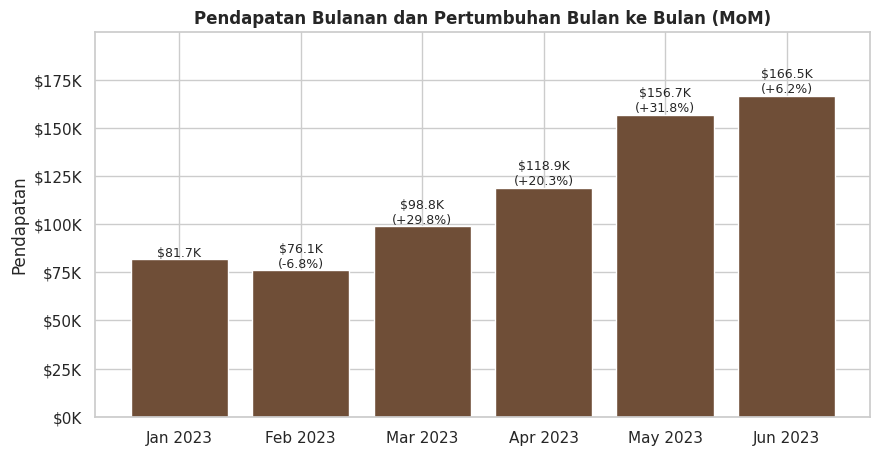

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(monthly["month_label"], monthly["revenue"], color=WARNA)

for bar, g in zip(bars, monthly["mom_growth_pct"]):
    teks = f"${bar.get_height()/1000:,.1f}K"
    if not np.isnan(g):
        teks += f"\n({g:+.1f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), teks,
            ha="center", va="bottom", fontsize=9)

ax.set_title("Pendapatan Bulanan dan Pertumbuhan Bulan ke Bulan (MoM)")
ax.set_ylabel("Pendapatan")
ax.set_ylim(0, monthly["revenue"].max() * 1.2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
plt.show()

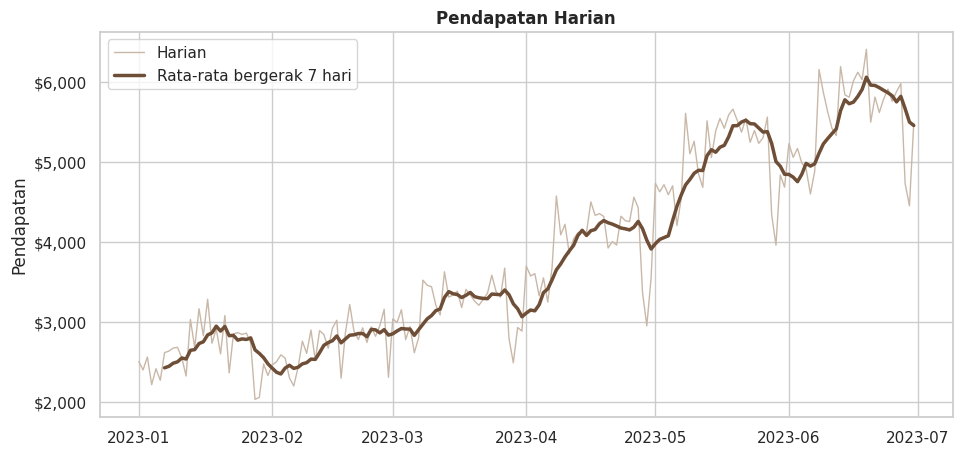

Hari terbaik   : 2023-06-19 ($6,404)
Hari terendah  : 2023-01-28 ($2,037)
Rata-rata harian Januari : $2,635
Rata-rata harian Juni    : $5,550


In [13]:
daily = df.groupby("transaction_date")["revenue"].sum()
ma7 = daily.rolling(7).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily.index, daily.values, color="#c9b8a8", linewidth=1, label="Harian")
ax.plot(ma7.index, ma7.values, color=WARNA, linewidth=2.5, label="Rata-rata bergerak 7 hari")
ax.set_title("Pendapatan Harian")
ax.set_ylabel("Pendapatan")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend()
plt.show()

print(f"Hari terbaik   : {daily.idxmax().date()} (${daily.max():,.0f})")
print(f"Hari terendah  : {daily.idxmin().date()} (${daily.min():,.0f})")
print(f"Rata-rata harian Januari : ${daily[daily.index.month == 1].mean():,.0f}")
print(f"Rata-rata harian Juni    : ${daily[daily.index.month == 6].mean():,.0f}")

In [14]:
jan = monthly.loc[0, "revenue"]
jun = monthly.loc[monthly.index[-1], "revenue"]
print(f"Pendapatan Juni dibanding Januari: {jun / jan:.2f}x ({(jun / jan - 1) * 100:+.1f}%)")

Pendapatan Juni dibanding Januari: 2.04x (+103.8%)


**Insight Q1:** Pendapatan naik sekitar dua kali lipat dari Januari ke Juni. Penurunan di Februari hanya efek kalender: bulannya lebih pendek, dan rata-rata pendapatan per hari justru naik tipis. Pertumbuhan paling kencang terjadi di Maret sampai Mei, lalu melambat di Juni. Karena data hanya mencakup enam bulan, belum bisa dipastikan apakah kenaikan ini tren bisnis yang berkelanjutan atau pola musiman (musim semi dan panas).

### Q2. Bagaimana perbandingan performa ketiga toko?

In [15]:
store = (
    df.groupby("store_location")
      .agg(revenue=("revenue", "sum"), lines=("transaction_id", "count"), qty=("transaction_qty", "sum"))
      .assign(
          share_pct=lambda x: x["revenue"] / x["revenue"].sum() * 100,
          rev_per_line=lambda x: x["revenue"] / x["lines"],
          items_per_line=lambda x: x["qty"] / x["lines"],
      )
      .sort_values("revenue", ascending=False)
)
store

,revenue,lines,qty,share_pct,rev_per_line,items_per_line
store_location,,,,,,
Hell's Kitchen,"236,511.17",50735,71737,33.84,4.66,1.41
Astoria,"232,243.91",50599,70991,33.23,4.59,1.40
Lower Manhattan,"230,057.25",47782,71742,32.92,4.81,1.50


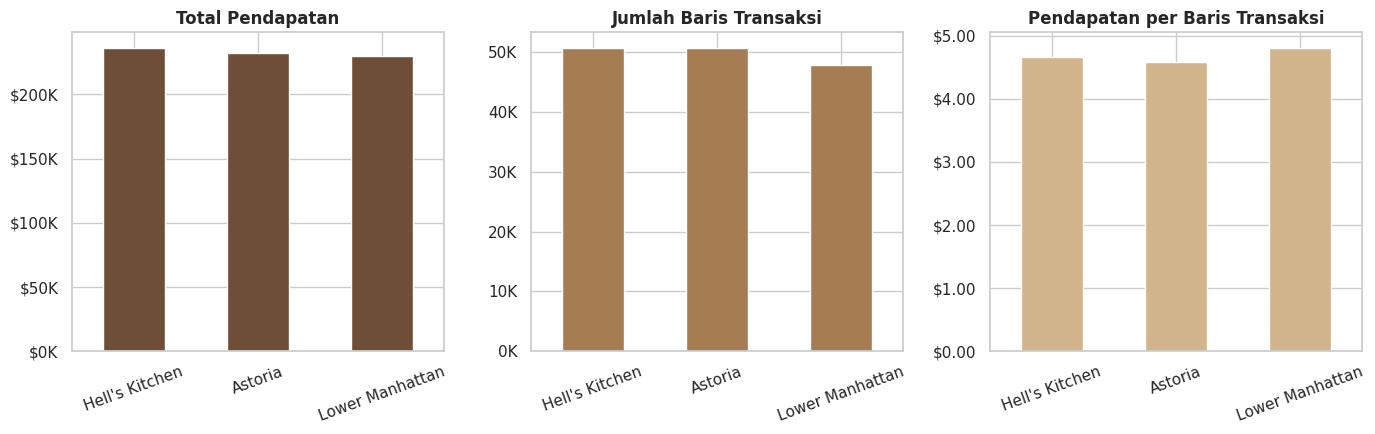

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

store["revenue"].plot.bar(ax=axes[0], color=WARNA, rot=20)
axes[0].set_title("Total Pendapatan")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))

store["lines"].plot.bar(ax=axes[1], color="#a67c52", rot=20)
axes[1].set_title("Jumlah Baris Transaksi")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}K"))

store["rev_per_line"].plot.bar(ax=axes[2], color="#d2b48c", rot=20)
axes[2].set_title("Pendapatan per Baris Transaksi")
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.2f}"))

for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

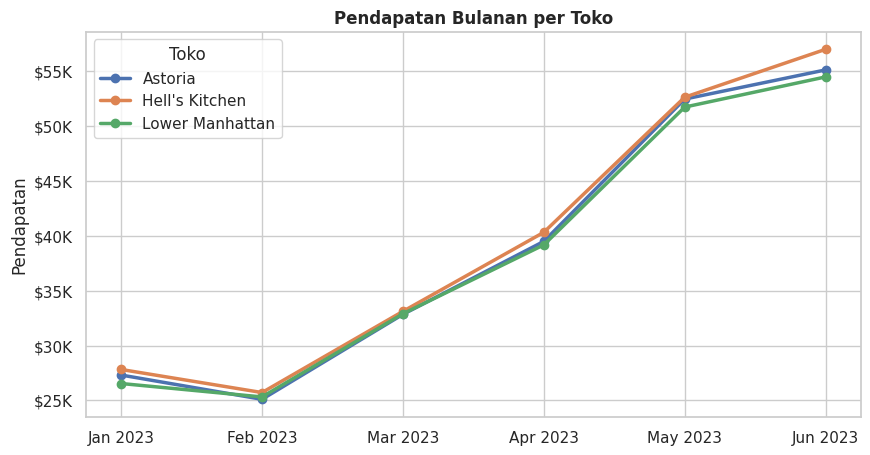

Selisih toko tertinggi vs terendah: 2.8%


In [17]:
store_month = df.pivot_table(index="month_label", columns="store_location",
                             values="revenue", aggfunc="sum")
store_month = store_month.loc[monthly["month_label"]]  # urutkan kronologis

ax = store_month.plot(marker="o", figsize=(10, 5), linewidth=2.5)
ax.set_title("Pendapatan Bulanan per Toko")
ax.set_xlabel("")
ax.set_ylabel("Pendapatan")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.legend(title="Toko")
plt.show()

selisih = (store["revenue"].max() - store["revenue"].min()) / store["revenue"].min() * 100
print(f"Selisih toko tertinggi vs terendah: {selisih:.1f}%")

**Insight Q2:** Ketiga toko hampir setara dalam total pendapatan, dengan selisih terbesar dan terkecil hanya sekitar 3%. Perbedaannya ada di polanya: Lower Manhattan punya jumlah transaksi paling sedikit tapi nilai per transaksi paling tinggi, sedangkan Astoria dan Hell's Kitchen lebih unggul di jumlah transaksi. Ketiganya juga tumbuh seirama dari bulan ke bulan, jadi pertumbuhan bukan berasal dari satu toko saja.

### Q3. Kategori dan produk apa yang menyumbang pendapatan terbesar?

In [18]:
cat = (
    df.groupby("product_category")
      .agg(revenue=("revenue", "sum"), lines=("transaction_id", "count"),
           qty=("transaction_qty", "sum"), avg_price=("unit_price", "mean"))
      .assign(
          revenue_share_pct=lambda x: x["revenue"] / x["revenue"].sum() * 100,
          lines_share_pct=lambda x: x["lines"] / x["lines"].sum() * 100,
      )
      .sort_values("revenue", ascending=False)
)
cat

,revenue,lines,qty,avg_price,revenue_share_pct,lines_share_pct
product_category,,,,,,
Coffee,"269,952.45",58416,89250,3.02,38.63,39.17
Tea,"196,405.95",45449,69737,2.82,28.11,30.48
Bakery,"82,315.64",22796,23214,3.55,11.78,15.29
Drinking Chocolate,"72,416.00",11468,17457,4.15,10.36,7.69
Coffee beans,"40,085.25",1753,1828,21.02,5.74,1.18
Branded,"13,607.00",747,776,17.72,1.95,0.50
Loose Tea,"11,213.60",1210,1210,9.27,1.60,0.81
Flavours,"8,408.80",6790,10511,0.80,1.20,4.55
Packaged Chocolate,"4,407.64",487,487,9.05,0.63,0.33


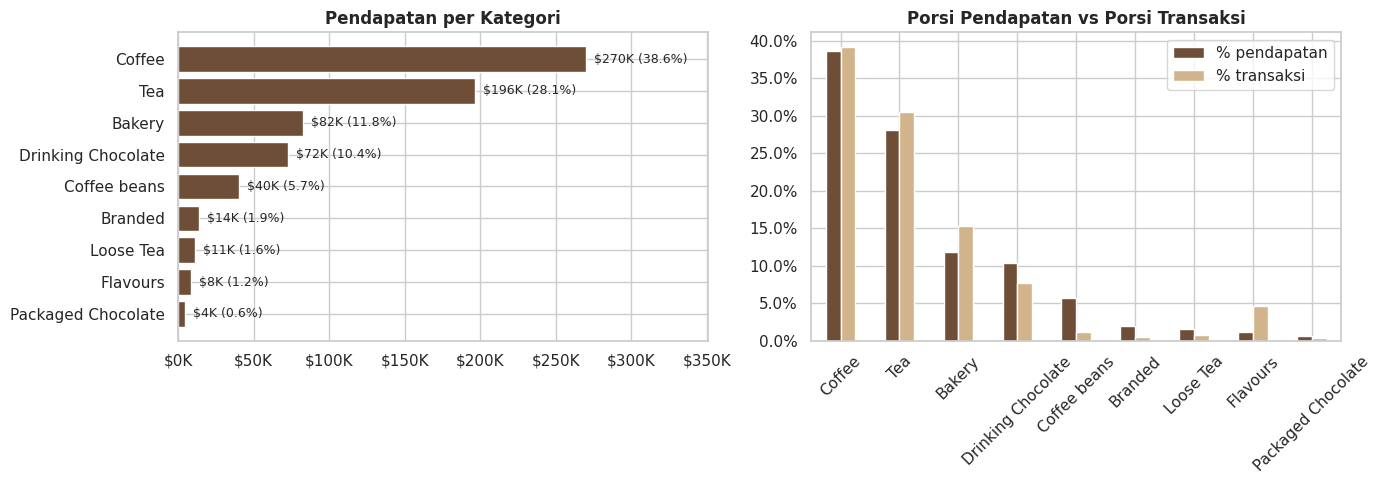

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

c = cat.sort_values("revenue")
axes[0].barh(c.index, c["revenue"], color=WARNA)
for i, (v, s) in enumerate(zip(c["revenue"], c["revenue_share_pct"])):
    axes[0].text(v, i, f"  ${v/1000:,.0f}K ({s:.1f}%)", va="center", fontsize=9)
axes[0].set_title("Pendapatan per Kategori")
axes[0].set_xlim(0, c["revenue"].max() * 1.3)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))

# Perbandingan porsi pendapatan vs porsi jumlah transaksi
cmp = cat[["revenue_share_pct", "lines_share_pct"]].rename(
    columns={"revenue_share_pct": "% pendapatan", "lines_share_pct": "% transaksi"})
cmp.plot.bar(ax=axes[1], color=[WARNA, "#d2b48c"], rot=45)
axes[1].set_title("Porsi Pendapatan vs Porsi Transaksi")
axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.show()

In [20]:
# Produk: 10 teratas dan 10 terbawah berdasarkan pendapatan
prod = (
    df.groupby(["product_category", "product_detail"])
      .agg(revenue=("revenue", "sum"), qty=("transaction_qty", "sum"), unit_price=("unit_price", "first"))
      .reset_index()
      .sort_values("revenue", ascending=False)
      .reset_index(drop=True)
)
print("10 produk dengan pendapatan tertinggi:")
display(prod.head(10))
print("10 produk dengan pendapatan terendah:")
display(prod.tail(10))

10 produk dengan pendapatan tertinggi:


,product_category,product_detail,revenue,qty,unit_price
0,Drinking Chocolate,Sustainably Grown Organic Lg,"21,151.75",4453,4.75
1,Drinking Chocolate,Dark chocolate Lg,"21,006.00",4668,4.50
2,Coffee,Latte Rg,"19,112.25",4497,4.25
3,Coffee,Cappuccino Lg,"17,641.75",4151,4.25
4,Tea,Morning Sunrise Chai Lg,"17,384.00",4346,4.00
5,Coffee,Latte,"17,257.50",4602,3.75
6,Coffee,Jamaican Coffee River Lg,"16,481.25",4395,3.75
7,Drinking Chocolate,Sustainably Grown Organic Rg,"16,233.75",4329,3.75
8,Coffee,Cappuccino,"15,997.50",4266,3.75
9,Coffee,Brazilian Lg,"15,109.50",4317,3.50


10 produk dengan pendapatan terendah:


,product_category,product_detail,revenue,qty,unit_price
70,Loose Tea,Morning Sunrise Chai,"1,596.00",168,9.50
71,Loose Tea,Serenity Green Tea,"1,470.75",159,9.25
72,Loose Tea,English Breakfast,"1,440.95",161,8.95
73,Loose Tea,Peppermint,"1,369.35",153,8.95
74,Loose Tea,Traditional Blend Chai,"1,369.35",153,8.95
75,Loose Tea,Lemon Grass,"1,360.40",152,8.95
76,Coffee beans,Guatemalan Sustainably Grown,"1,340.00",134,10.00
77,Loose Tea,Spicy Eye Opener Chai,"1,335.90",122,10.95
78,Loose Tea,Earl Grey,"1,270.90",142,8.95
79,Packaged Chocolate,Dark chocolate,755.20,118,6.40


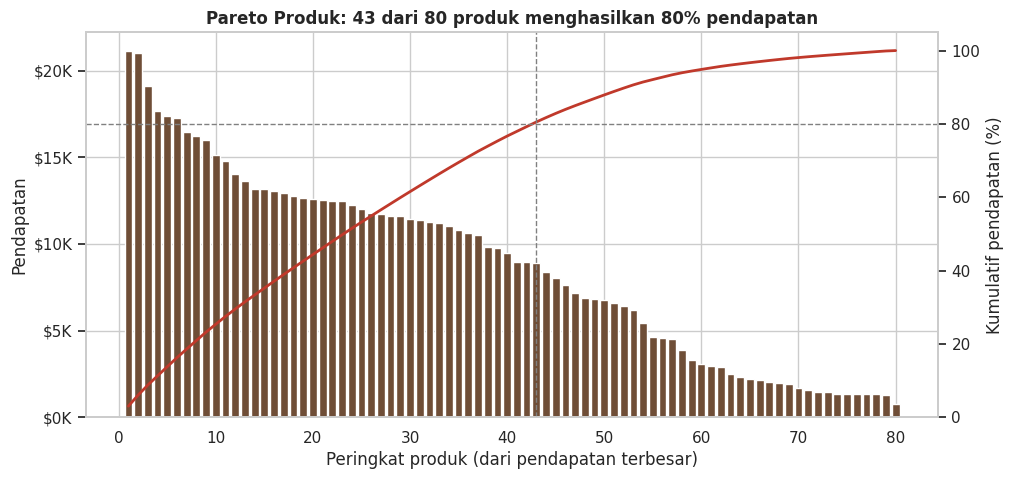

In [21]:
# Analisis Pareto pada level produk
prod["cum_share_pct"] = prod["revenue"].cumsum() / prod["revenue"].sum() * 100
n80 = int((prod["cum_share_pct"] < 80).sum() + 1)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(range(1, len(prod) + 1), prod["revenue"], color=WARNA)
ax1.set_xlabel("Peringkat produk (dari pendapatan terbesar)")
ax1.set_ylabel("Pendapatan")
ax1.yaxis.set_major_locator(mtick.MultipleLocator(5000))
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))

ax2 = ax1.twinx()
ax2.plot(range(1, len(prod) + 1), prod["cum_share_pct"], color="#c0392b", linewidth=2)
ax2.axhline(80, color="grey", linestyle="--", linewidth=1)
ax2.axvline(n80, color="grey", linestyle="--", linewidth=1)
ax2.set_ylabel("Kumulatif pendapatan (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax1.set_title(f"Pareto Produk: {n80} dari {len(prod)} produk menghasilkan 80% pendapatan")
plt.show()

In [22]:
# Barang bernilai tinggi: sedikit transaksi, tapi kontribusi besar
mahal = prod[prod["unit_price"] >= 20].copy()
mahal["revenue_share_pct"] = mahal["revenue"] / df["revenue"].sum() * 100
print(f"Produk berharga >= $20 menyumbang {mahal['revenue_share_pct'].sum():.1f}% pendapatan")
mahal

Produk berharga >= $20 menyumbang 4.3% pendapatan


,product_category,product_detail,revenue,qty,unit_price,cum_share_pct,revenue_share_pct
26,Coffee beans,Civet Cat,"11,700.00",260,45.00,56.57,1.67
52,Branded,I Need My Bean! T-shirt,"6,163.00",221,28.00,90.65,0.88
54,Coffee beans,Organic Decaf Blend,"4,657.50",206,28.00,92.10,0.67
55,Coffee beans,Ethiopia,"4,578.00",218,21.00,92.76,0.66
59,Coffee beans,Primo Espresso Roast,"3,067.50",150,20.45,94.86,0.44


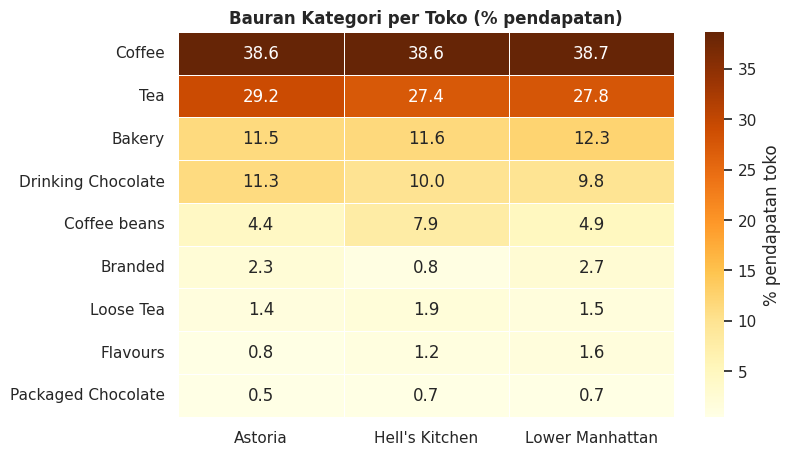

In [23]:
# Porsi pendapatan tiap kategori di masing-masing toko (%)
porsi = df.pivot_table(index="product_category", columns="store_location",
                       values="revenue", aggfunc="sum")
porsi = (porsi / porsi.sum() * 100).loc[cat.index]

plt.figure(figsize=(8, 5))
sns.heatmap(porsi, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.5,
            cbar_kws={"label": "% pendapatan toko"})
plt.title("Bauran Kategori per Toko (% pendapatan)")
plt.xlabel("")
plt.ylabel("")
plt.show()

**Insight Q3:**
- Coffee dan Tea menyumbang sekitar dua pertiga pendapatan. Ditambah Bakery dan Drinking Chocolate, empat kategori ini mencakup sekitar 89% pendapatan.
- Coffee beans menarik: porsinya terhadap pendapatan (sekitar 5,7%) jauh lebih besar dari porsinya terhadap jumlah transaksi (sekitar 1,2%) karena harga satuannya tinggi. Hell's Kitchen paling kuat di kategori ini (sekitar 8% pendapatannya, dibanding 4-5% di dua toko lain). Sebaliknya Flavours (sirup) sering dibeli tapi hampir tidak menambah pendapatan.
- Pendapatan cukup tersebar, butuh sekitar separuh dari seluruh produk untuk mencapai 80% pendapatan, jadi menu tidak terlalu bergantung pada beberapa produk saja.

### Q4. Kapan jam dan hari tersibuk, dan apakah polanya sama di setiap toko?

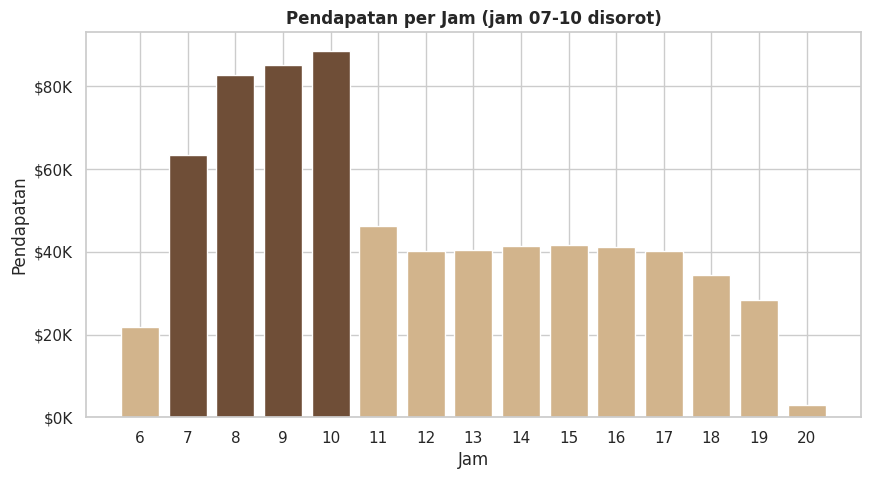

Jam 07.00-10.59 menyumbang 45.8% dari total pendapatan


In [24]:
hourly = df.groupby("hour")["revenue"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
warna_jam = [WARNA if 7 <= h <= 10 else "#d2b48c" for h in hourly.index]
ax.bar(hourly.index, hourly.values, color=warna_jam)
ax.set_title("Pendapatan per Jam (jam 07-10 disorot)")
ax.set_xlabel("Jam")
ax.set_ylabel("Pendapatan")
ax.set_xticks(hourly.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
plt.show()

rush = df[df["hour"].between(7, 10)]["revenue"].sum() / df["revenue"].sum() * 100
print(f"Jam 07.00-10.59 menyumbang {rush:.1f}% dari total pendapatan")

In [ ]:
periode = (df.groupby("period", observed=True)
             .agg(revenue=("revenue", "sum"), jam=("hour", "nunique"))
             .assign(share_pct=lambda x: x["revenue"] / x["revenue"].sum() * 100,
                     rev_per_jam=lambda x: x["revenue"] / x["jam"]))
periode

,revenue,jam,share_pct,rev_per_jam
period,,,,
Pagi (06-10),"341,969.53",5,48.94,"68,393.91"
Siang (11-14),"168,184.12",4,24.07,"42,046.03"
Sore (15-17),"122,990.16",3,17.60,"40,996.72"
Malam (18-20),"65,668.52",3,9.40,"21,889.51"


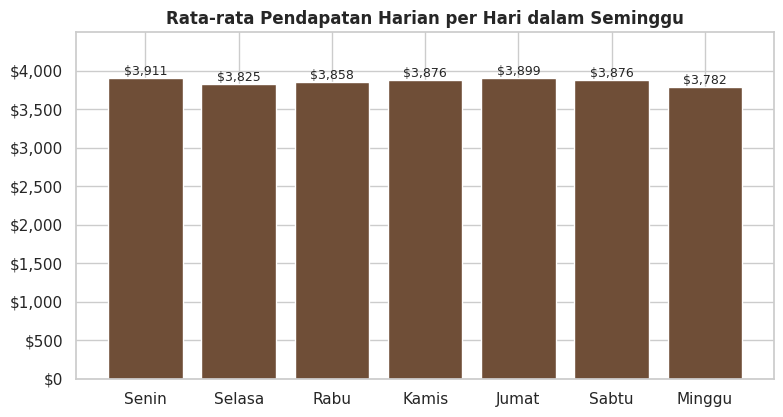

Selisih hari tertinggi vs terendah: 3.4%


In [25]:
# Rata-rata pendapatan harian per hari dalam seminggu
per_hari = df.groupby(["transaction_date", "weekday"], observed=True)["revenue"].sum().reset_index()
avg_hari = per_hari.groupby("weekday", observed=True)["revenue"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(avg_hari.index.astype(str), avg_hari.values, color=WARNA)
ax.set_title("Rata-rata Pendapatan Harian per Hari dalam Seminggu")
ax.set_xlabel("")
ax.set_ylim(0, avg_hari.max() * 1.15)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}"))
for i, v in enumerate(avg_hari.values):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.show()

print(f"Selisih hari tertinggi vs terendah: {(avg_hari.max() / avg_hari.min() - 1) * 100:.1f}%")

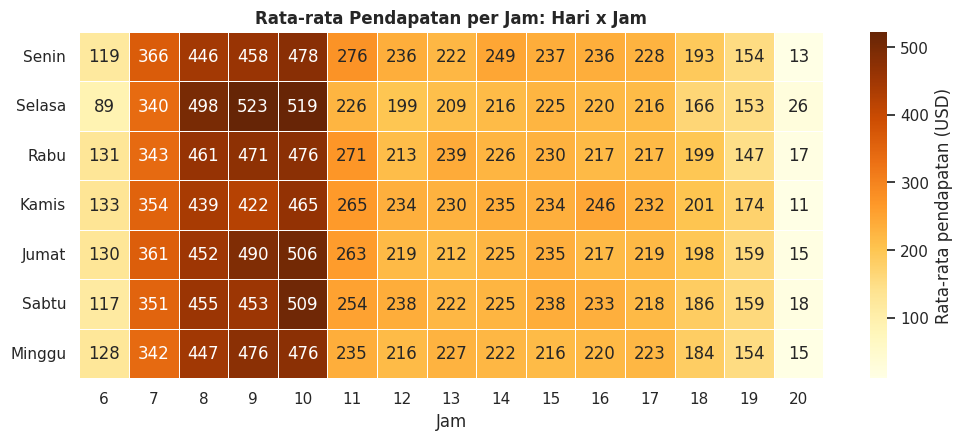

In [26]:
# Heatmap: rata-rata pendapatan per jam untuk tiap hari (dinormalisasi per jumlah hari)
hari_per_weekday = df.drop_duplicates("transaction_date").groupby("weekday", observed=True).size()
heat = df.pivot_table(index="weekday", columns="hour", values="revenue", aggfunc="sum", observed=True)
heat = heat.div(hari_per_weekday, axis=0)

plt.figure(figsize=(12, 4.5))
sns.heatmap(heat, cmap="YlOrBr", annot=True, fmt=".0f", linewidths=0.5,
            cbar_kws={"label": "Rata-rata pendapatan (USD)"})
plt.title("Rata-rata Pendapatan per Jam: Hari x Jam")
plt.xlabel("Jam")
plt.ylabel("")
plt.show()

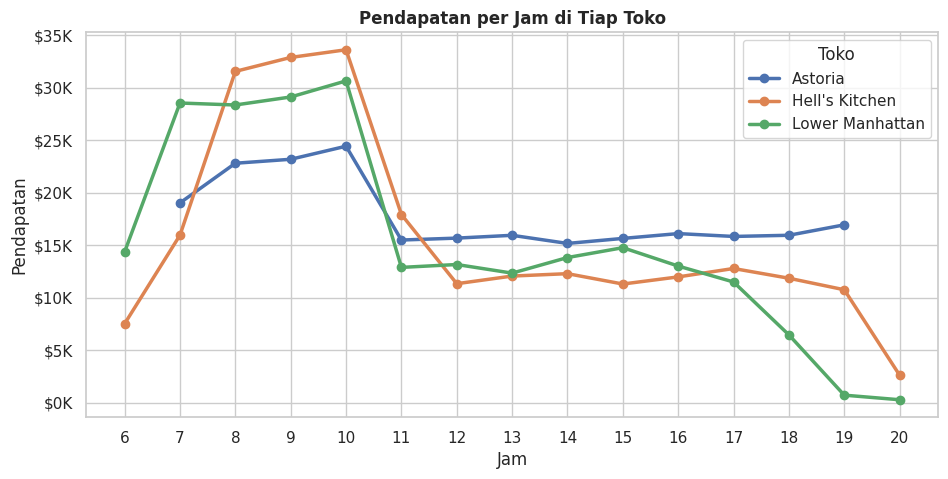

In [27]:
# Pola jam per toko
store_hour = df.pivot_table(index="hour", columns="store_location", values="revenue", aggfunc="sum")

ax = store_hour.plot(marker="o", figsize=(11, 5), linewidth=2.5)
ax.set_title("Pendapatan per Jam di Tiap Toko")
ax.set_xlabel("Jam")
ax.set_ylabel("Pendapatan")
ax.set_xticks(store_hour.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.legend(title="Toko")
plt.show()

In [28]:
# Porsi pendapatan tiap toko menurut periode hari
tabel = (df.pivot_table(index="store_location", columns="period", values="revenue",
                        aggfunc="sum", observed=True))
(tabel.div(tabel.sum(axis=1), axis=0) * 100).round(1)

period,Pagi (06-10),Siang (11-14),Sore (15-17),Malam (18-20)
store_location,,,,
Astoria,38.50,26.80,20.50,14.20
Hell's Kitchen,51.40,22.70,15.30,10.70
Lower Manhattan,56.90,22.70,17.10,3.30


**Insight Q4:**
- Jam sibuk jelas ada pada pagi hari. Jam 07.00 sampai 10.59 menyumbang sekitar 46% pendapatan, dengan puncak di jam 10. Setelah jam 11, pendapatan turun ke kisaran yang stabil sepanjang siang dan sore.
- Pola hari dalam seminggu hampir datar. Perbedaan hari tertinggi dan terendah hanya sekitar 3%, jadi penjadwalan staf lebih perlu mengikuti jam daripada hari.
- Pola jam berbeda antar toko. **Lower Manhattan** (sekitar 57%) dan **Hell's Kitchen** (sekitar 51%) paling bergantung pada pagi hari (jam 06-10), sedangkan **Astoria** lebih merata (sekitar 39% di pagi hari) dan masih menyumbang sekitar 14% pendapatannya di jam 18-20. Di Lower Manhattan, porsi jam 18-20 hanya sekitar 3% dan hampir tidak ada pendapatan di jam 19-20.

### Q5. Apa yang mendorong pertumbuhan: jumlah transaksi, nilai per transaksi, atau kategori tertentu?

Pendapatan dapat diuraikan menjadi: **pendapatan = jumlah transaksi x rata-rata pendapatan per transaksi**. Dengan membandingkan indeks keduanya (Januari = 100), dapat dilihat komponen mana yang lebih banyak berkontribusi.

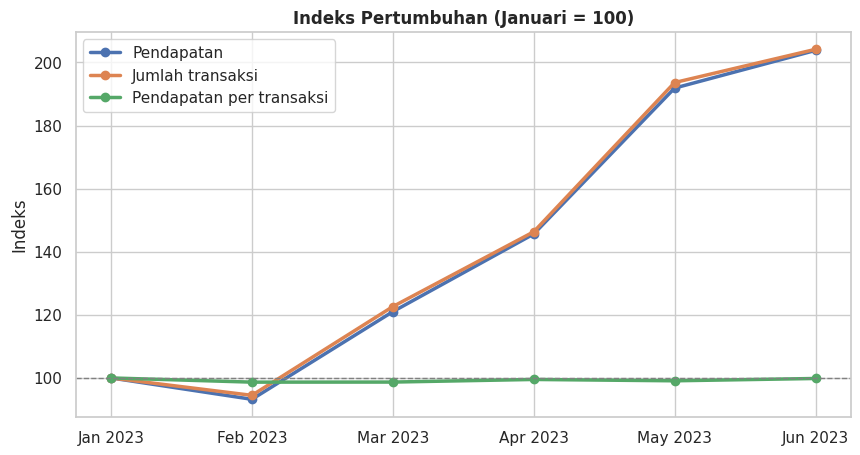

,month_label,lines,rev_per_line,items_per_line
0,Jan 2023,17314,4.72,1.44
1,Feb 2023,16359,4.65,1.44
2,Mar 2023,21229,4.66,1.43
3,Apr 2023,25335,4.69,1.44
4,May 2023,33527,4.67,1.44
5,Jun 2023,35352,4.71,1.44


In [29]:
dekomposisi = monthly[["month_label", "revenue", "lines", "qty"]].copy()
dekomposisi["rev_per_line"] = dekomposisi["revenue"] / dekomposisi["lines"]
dekomposisi["items_per_line"] = dekomposisi["qty"] / dekomposisi["lines"]

indeks = dekomposisi.set_index("month_label")[["revenue", "lines", "rev_per_line"]]
indeks = indeks / indeks.iloc[0] * 100
indeks.columns = ["Pendapatan", "Jumlah transaksi", "Pendapatan per transaksi"]

ax = indeks.plot(marker="o", figsize=(10, 5), linewidth=2.5)
ax.set_title("Indeks Pertumbuhan (Januari = 100)")
ax.set_xlabel("")
ax.set_ylabel("Indeks")
ax.axhline(100, color="grey", linestyle="--", linewidth=1)
plt.show()

dekomposisi[["month_label", "lines", "rev_per_line", "items_per_line"]]

In [30]:
# Pertumbuhan per kategori: Juni dibanding Januari
cat_month = df.pivot_table(index="product_category", columns="month_label",
                           values="revenue", aggfunc="sum")
cat_month = cat_month[monthly["month_label"]]

pertumbuhan = pd.DataFrame({
    "Jan": cat_month.iloc[:, 0],
    "Jun": cat_month.iloc[:, -1],
})
pertumbuhan["Kelipatan Jun/Jan"] = pertumbuhan["Jun"] / pertumbuhan["Jan"]
pertumbuhan["Tambahan USD"] = pertumbuhan["Jun"] - pertumbuhan["Jan"]
pertumbuhan["Kontribusi ke kenaikan (%)"] = pertumbuhan["Tambahan USD"] / pertumbuhan["Tambahan USD"].sum() * 100
pertumbuhan.sort_values("Tambahan USD", ascending=False)

,Jan,Jun,Kelipatan Jun/Jan,Tambahan USD,Kontribusi ke kenaikan (%)
product_category,,,,,
Coffee,"31,256.85","64,789.00",2.07,"33,532.15",39.54
Tea,"22,621.95","46,243.15",2.04,"23,621.20",27.85
Bakery,"9,535.75","19,251.27",2.02,"9,715.52",11.46
Drinking Chocolate,"8,337.75","17,106.00",2.05,"8,768.25",10.34
Coffee beans,"5,245.25","9,912.65",1.89,"4,667.40",5.50
Branded,"1,890.00","3,413.00",1.81,"1,523.00",1.80
Loose Tea,"1,293.85","2,770.65",2.14,"1,476.80",1.74
Flavours,974.40,"2,008.00",2.06,"1,033.60",1.22
Packaged Chocolate,521.94,992.16,1.90,470.22,0.55


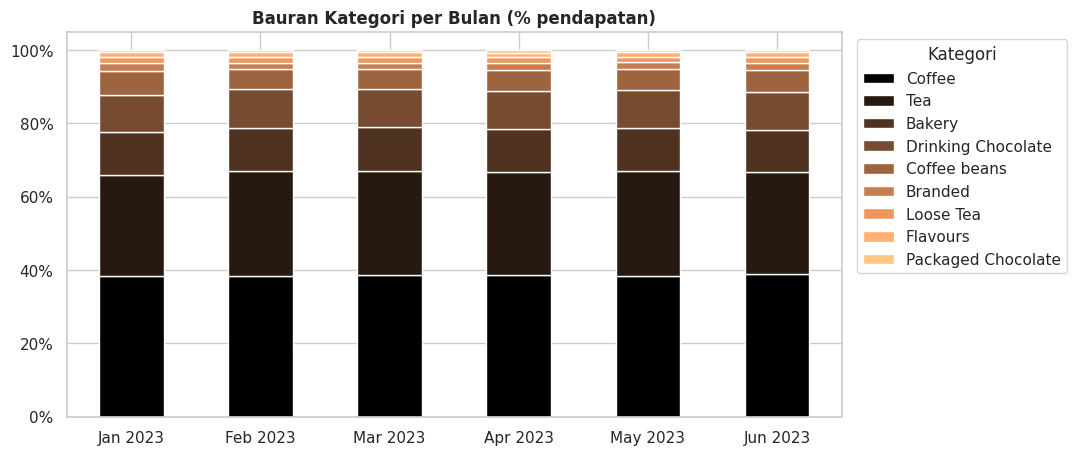

In [31]:
# Apakah bauran kategori berubah dari Januari ke Juni?
bauran = cat_month.div(cat_month.sum(axis=0), axis=1) * 100
bauran = bauran.loc[cat.index]  # urut dari kategori terbesar

ax = bauran.T.plot.bar(stacked=True, figsize=(10, 5), colormap="copper", rot=0)
ax.set_title("Bauran Kategori per Bulan (% pendapatan)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title="Kategori", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

**Insight Q5:** Lihat grafik indeks dan tabel di atas. Kenaikan pendapatan hampir seluruhnya mengikuti kenaikan jumlah transaksi, sedangkan pendapatan per transaksi relatif stabil. Setiap kategori juga tumbuh dengan kelipatan yang mirip, sehingga bauran kategori bergeser sangat sedikit. Artinya pertumbuhan terjadi merata di seluruh menu, bukan karena satu produk andalan atau kenaikan harga.

### Ringkasan Angka Kunci

In [32]:
rev_store = df.groupby("store_location")["revenue"].sum()
jam_puncak = hourly.idxmax()
top_cat = cat["revenue_share_pct"].head(2)

print(f"1. Total pendapatan Jan-Jun 2023        : ${total_rev:,.0f}")
print(f"2. Pendapatan Juni vs Januari           : {jun / jan:.2f}x")
print(f"3. Toko dengan pendapatan tertinggi     : {rev_store.idxmax()} (${rev_store.max():,.0f})")
print(f"4. Selisih toko tertinggi vs terendah   : {selisih:.1f}%")
print(f"5. Dua kategori teratas                 : {', '.join(top_cat.index)} ({top_cat.sum():.1f}% pendapatan)")
print(f"6. Produk yang membentuk 80% pendapatan : {n80} dari {len(prod)}")
print(f"7. Jam puncak                           : {jam_puncak}.00 | jam 07-10 = {rush:.1f}% pendapatan")
print(f"8. Selisih hari terbaik vs terburuk     : {(avg_hari.max() / avg_hari.min() - 1) * 100:.1f}%")

1. Total pendapatan Jan-Jun 2023        : $698,812
2. Pendapatan Juni vs Januari           : 2.04x
3. Toko dengan pendapatan tertinggi     : Hell's Kitchen ($236,511)
4. Selisih toko tertinggi vs terendah   : 2.8%
5. Dua kategori teratas                 : Coffee, Tea (66.7% pendapatan)
6. Produk yang membentuk 80% pendapatan : 43 dari 80
7. Jam puncak                           : 10.00 | jam 07-10 = 45.8% pendapatan
8. Selisih hari terbaik vs terburuk     : 3.4%


## 6. Kesimpulan dan Rekomendasi

### Kesimpulan

| Pertanyaan | Jawaban singkat |
|-----------|-----------------|
| Q1 Tren | Pendapatan Juni sekitar 2x Januari. Penurunan Februari hanya karena bulannya lebih pendek, dan pertumbuhan melambat di Juni. |
| Q2 Toko | Ketiga toko nyaris setara (selisih sekitar 3%) dan tumbuh seirama. Perbedaannya ada di pola jam, bukan di total. |
| Q3 Produk | Coffee dan Tea menyumbang sekitar 2/3 pendapatan. Coffee beans kecil dari sisi transaksi tapi besar dari sisi nilai. |
| Q4 Waktu | Jam 07-10 menghasilkan sekitar 46% pendapatan. Hari dalam seminggu hampir tidak berbeda. |
| Q5 Pendorong | Pertumbuhan dipicu naiknya jumlah transaksi secara merata di semua kategori, bukan kenaikan harga atau satu produk andalan. |

### Rekomendasi

1. **Fokuskan staf dan stok pada jam 07-10.** Hampir separuh pendapatan lahir di empat jam ini. Pastikan stok kopi, teh, dan pastry tidak habis sebelum jam 10, dan tempatkan staf terbaik di jam tersebut. Karena pola antar hari hampir sama, jadwal cukup disusun berdasarkan jam, bukan hari.
2. **Uji coba promo di jam sepi (11.00-17.00).** Pendapatan per jam di rentang ini hanya sekitar separuh dari jam puncak. Contohnya paket kopi + pastry atau diskon siang hari. Ukur dulu pada satu toko sebelum diterapkan ke semua cabang.
3. **Evaluasi jam malam di Lower Manhattan.** Pendapatan setelah jam 18.00 sangat kecil dibanding Astoria dan Hell's Kitchen. Pertimbangkan memangkas jam tutup, atau menguji promo malam sebelum memutuskan. Sebaliknya, pertahankan operasional malam di Astoria yang masih stabil.
4. **Perkuat penjualan biji kopi.** Kategori ini menyumbang sekitar 5,7% pendapatan dari hanya sekitar 1,2% transaksi, jadi setiap tambahan penjualan bernilai besar. Hell's Kitchen punya porsi biji kopi tertinggi, sehingga cara display dan penawarannya layak dicoba di dua toko lain.
5. **Pantau efektivitas produk berpendapatan rendah.** Sirup (Flavours) sering dibeli tapi kontribusi pendapatannya kecil. Pertimbangkan menjadikannya add-on berbayar atau bundel agar tidak sekadar menambah beban layanan.
6. **Lanjutkan pemantauan setelah Juni.** Data baru mencakup enam bulan, jadi perlu data Juli ke atas untuk memastikan apakah pertumbuhan bertahan atau merupakan efek musiman.

## 7. Keterbatasan Analisis

- **Hanya enam bulan data.** Tidak bisa memisahkan tren jangka panjang dari pola musiman, dan tidak ada pembanding tahun sebelumnya.
- **Tidak ada ID pesanan atau pelanggan.** Analisis keranjang belanja (item yang dibeli bersamaan), retensi, dan segmentasi pelanggan (RFM) tidak bisa dilakukan. "Rata-rata per transaksi" di sini adalah per baris item, bukan per struk.
- **Tidak ada data biaya.** Yang dianalisis adalah pendapatan, bukan laba. Produk berpendapatan rendah belum tentu tidak menguntungkan, dan sebaliknya.
- **Tidak ada data eksternal.** Faktor seperti cuaca, hari libur, promo, atau kampanye pemasaran tidak tercatat, sehingga penyebab perubahan pendapatan hanya bisa diduga, bukan dibuktikan.
- **Mata uang diasumsikan USD** berdasarkan lokasi toko.
